## Get the Data

Either use the provided .csv file or (optionally) get fresh (the freshest?) data from running an SQL query on StackExchange: 

Follow this link to run the query from [StackExchange](https://data.stackexchange.com/stackoverflow/query/675441/popular-programming-languages-per-over-time-eversql-com) to get your own .csv file

<code>
select dateadd(month, datediff(month, 0, q.CreationDate), 0) m, TagName, count(*)
from PostTags pt
join Posts q on q.Id=pt.PostId
join Tags t on t.Id=pt.TagId
where TagName in ('java','c','c++','python','c#','javascript','assembly','php','perl','ruby','visual basic','swift','r','object-c','scratch','go','swift','delphi')
and q.CreationDate < dateadd(month, datediff(month, 0, getdate()), 0)
group by dateadd(month, datediff(month, 0, q.CreationDate), 0), TagName
order by dateadd(month, datediff(month, 0, q.CreationDate), 0)
</code>

## Import Statements

In [57]:
import pandas as pd
import matplotlib.pyplot as plt

## Data Exploration

**Challenge**: Read the .csv file and store it in a Pandas dataframe

In [3]:
df = pd.read_csv('QueryResults.csv', header=0, names=["DATE", "TAG", "POSTS"])
print(df)

                     DATE       TAG  POSTS
0     2008-07-01 00:00:00        c#      3
1     2008-08-01 00:00:00  assembly      8
2     2008-08-01 00:00:00         c     81
3     2008-08-01 00:00:00        c#    503
4     2008-08-01 00:00:00       c++    164
...                   ...       ...    ...
3035  2026-10-01 00:00:00       php     26
3036  2026-10-01 00:00:00    python    109
3037  2026-10-01 00:00:00         r     41
3038  2026-10-01 00:00:00      ruby      4
3039  2026-10-01 00:00:00     swift      9

[3040 rows x 3 columns]


**Challenge**: Examine the first 5 rows and the last 5 rows of the of the dataframe

In [7]:
print(df.head())
print(df.tail())

                  DATE       TAG  POSTS
0  2008-07-01 00:00:00        c#      3
1  2008-08-01 00:00:00  assembly      8
2  2008-08-01 00:00:00         c     81
3  2008-08-01 00:00:00        c#    503
4  2008-08-01 00:00:00       c++    164
                     DATE     TAG  POSTS
3035  2026-10-01 00:00:00     php     26
3036  2026-10-01 00:00:00  python    109
3037  2026-10-01 00:00:00       r     41
3038  2026-10-01 00:00:00    ruby      4
3039  2026-10-01 00:00:00   swift      9


**Challenge:** Check how many rows and how many columns there are. 
What are the dimensions of the dataframe?

In [9]:
df.shape

(3040, 3)

**Challenge**: Count the number of entries in each column of the dataframe

In [13]:
df.count()

DATE     3040
TAG      3040
POSTS    3040
dtype: int64

**Challenge**: Calculate the total number of post per language.
Which Programming language has had the highest total number of posts of all time?

In [29]:
df.groupby(['TAG'])['POSTS'].sum()

TAG
assembly        45063
c              407980
c#            1621629
c++            813974
delphi          52548
go              74450
java          1914160
javascript    2521450
perl            68296
php           1460701
python        2204249
r              510340
ruby           229118
swift          336085
Name: POSTS, dtype: int64

Some languages are older (e.g., C) and other languages are newer (e.g., Swift). The dataset starts in September 2008.

**Challenge**: How many months of data exist per language? Which language had the fewest months with an entry? 


In [30]:
# df['DATE'] = pd.to_datetime(df['DATE'])
# total_months_per_tag = (
#     df.assign(year_month=df['DATE'].dt.to_period('M'))
#     .groupby('TAG')['year_month']
#     .nunique()
#     .reset_index(name='total_months')
# )
# total_months_per_tag
df.groupby('TAG').count()

,DATE,POSTS
TAG,,
assembly,219,219
c,219,219
c#,220,220
c++,219,219
delphi,219,219
go,204,204
java,219,219
javascript,219,219
perl,218,218


## Data Cleaning

Let's fix the date format to make it more readable. We need to use Pandas to change format from a string of "2008-07-01 00:00:00" to a datetime object with the format of "2008-07-01"

In [ ]:
# df['DATE'][1]
df.DATE[1]

Timestamp('2008-08-01 00:00:00')

In [34]:
type(df.DATE[1])

pandas.Timestamp

In [39]:
print(pd.to_datetime(df.DATE[1]))
df.DATE = pd.to_datetime(df.DATE)
df.head()

2008-08-01 00:00:00


,DATE,TAG,POSTS
0,2008-07-01,c#,3
1,2008-08-01,assembly,8
2,2008-08-01,c,81
3,2008-08-01,c#,503
4,2008-08-01,c++,164


## Data Manipulation



In [44]:
test_df = pd.DataFrame({'Age': ['Young', 'Young', 'Young', 'Young', 'Old', 'Old', 'Old', 'Old'],
                        'Actor': ['Jack', 'Arnold', 'Keanu', 'Sylvester', 'Jack', 'Arnold', 'Keanu', 'Sylvester'],
                        'Power': [100, 80, 25, 50, 99, 75, 5, 30]})
test_df

# test_df = pd.DataFrame({'Age': ['Young', 'Young', 'Young', 'Young', 'Old', 'Old', 'Old'],
#                         'Actor': ['Jack', 'Arnold', 'Keanu', 'Sylvester', 'Jack', 'Arnold', 'Keanu'],
#                         'Power': [100, 80, 25, 50, 99, 75, 5]})
# test_df

pivoted_df = test_df.pivot(index='Age', columns='Actor', values='Power')
pivoted_df

Actor,Arnold,Jack,Keanu,Sylvester
Age,,,,
Old,75,99,5,30
Young,80,100,25,50


**Challenge**: What are the dimensions of our new dataframe? How many rows and columns does it have? Print out the column names and print out the first 5 rows of the dataframe.

In [45]:
reshaped_df = df.pivot(index='DATE', columns='TAG', values='POSTS')
reshaped_df

TAG,assembly,c,c#,c++,delphi,go,java,javascript,perl,php,python,r,ruby,swift
DATE,,,,,,,,,,,,,,
2008-07-01,NaN,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2008-08-01,8.0,81.0,503.0,164.0,13.0,NaN,220.0,160.0,28.0,157.0,119.0,NaN,68.0,NaN
2008-09-01,28.0,320.0,1636.0,749.0,104.0,NaN,1119.0,629.0,128.0,471.0,533.0,6.0,285.0,NaN
2008-10-01,16.0,302.0,1982.0,804.0,112.0,NaN,1142.0,721.0,128.0,603.0,504.0,NaN,245.0,NaN
2008-11-01,16.0,257.0,1727.0,733.0,139.0,NaN,951.0,581.0,97.0,497.0,446.0,1.0,154.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-06-01,7.0,62.0,99.0,99.0,11.0,6.0,79.0,94.0,6.0,28.0,210.0,41.0,2.0,30.0
2026-07-01,4.0,39.0,66.0,95.0,4.0,4.0,68.0,69.0,5.0,23.0,134.0,54.0,2.0,15.0
2026-08-01,4.0,38.0,50.0,89.0,3.0,4.0,64.0,68.0,NaN,18.0,138.0,25.0,2.0,17.0


In [47]:
reshaped_df.tail()

TAG,assembly,c,c#,c++,delphi,go,java,javascript,perl,php,python,r,ruby,swift
DATE,,,,,,,,,,,,,,
2026-06-01,7.0,62.0,99.0,99.0,11.0,6.0,79.0,94.0,6.0,28.0,210.0,41.0,2.0,30.0
2026-07-01,4.0,39.0,66.0,95.0,4.0,4.0,68.0,69.0,5.0,23.0,134.0,54.0,2.0,15.0
2026-08-01,4.0,38.0,50.0,89.0,3.0,4.0,64.0,68.0,NaN,18.0,138.0,25.0,2.0,17.0
2026-09-01,5.0,44.0,53.0,83.0,5.0,7.0,39.0,54.0,3.0,14.0,114.0,30.0,4.0,15.0
2026-10-01,11.0,45.0,52.0,79.0,3.0,2.0,41.0,57.0,3.0,26.0,109.0,41.0,4.0,9.0


In [ ]:
print(reshaped_df.shape)


(220, 14)
TAG
assembly      219
c             219
c#            220
c++           219
delphi        219
go            204
java          219
javascript    219
perl          218
php           219
python        219
r             217
ruby          219
swift         210
dtype: int64


**Challenge**: Count the number of entries per programming language. Why might the number of entries be different? 

In [51]:
reshaped_df.count()

TAG
assembly      219
c             219
c#            220
c++           219
delphi        219
go            204
java          219
javascript    219
perl          218
php           219
python        219
r             217
ruby          219
swift         210
dtype: int64

In [55]:
reshaped_df.fillna(0, inplace=True)

TAG,assembly,c,c#,c++,delphi,go,java,javascript,perl,php,python,r,ruby,swift
DATE,,,,,,,,,,,,,,
2008-07-01,0.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2008-08-01,8.0,81.0,503.0,164.0,13.0,0.0,220.0,160.0,28.0,157.0,119.0,0.0,68.0,0.0
2008-09-01,28.0,320.0,1636.0,749.0,104.0,0.0,1119.0,629.0,128.0,471.0,533.0,6.0,285.0,0.0
2008-10-01,16.0,302.0,1982.0,804.0,112.0,0.0,1142.0,721.0,128.0,603.0,504.0,0.0,245.0,0.0
2008-11-01,16.0,257.0,1727.0,733.0,139.0,0.0,951.0,581.0,97.0,497.0,446.0,1.0,154.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-06-01,7.0,62.0,99.0,99.0,11.0,6.0,79.0,94.0,6.0,28.0,210.0,41.0,2.0,30.0
2026-07-01,4.0,39.0,66.0,95.0,4.0,4.0,68.0,69.0,5.0,23.0,134.0,54.0,2.0,15.0
2026-08-01,4.0,38.0,50.0,89.0,3.0,4.0,64.0,68.0,0.0,18.0,138.0,25.0,2.0,17.0


In [54]:
print(reshaped_df.isna().values.any())

False


## Data Visualisaton with with Matplotlib


**Challenge**: Use the [matplotlib documentation](https://matplotlib.org/3.2.1/api/_as_gen/matplotlib.pyplot.plot.html#matplotlib.pyplot.plot) to plot a single programming language (e.g., java) on a chart.

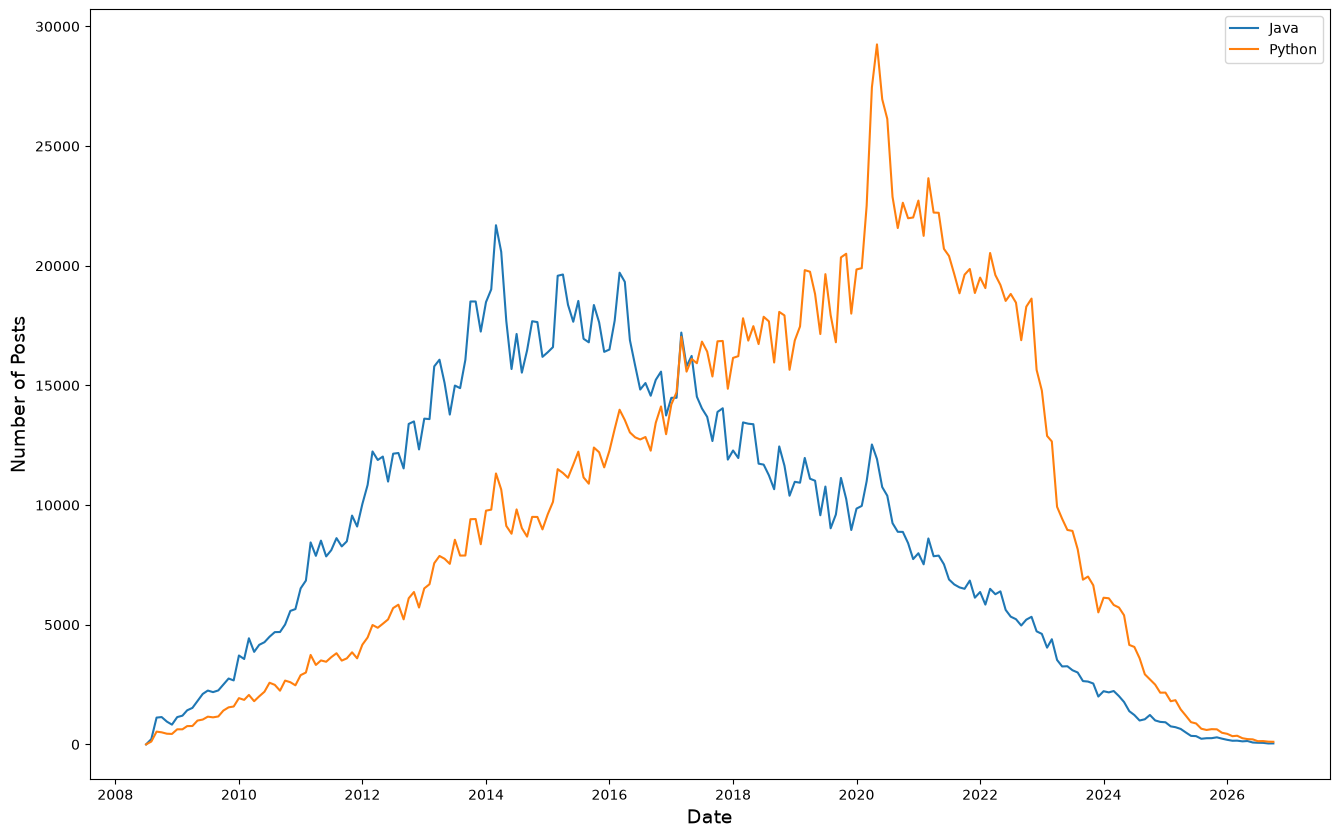

In [66]:
plt.figure(figsize=(16,10))
plt.xlabel('Date', fontsize=14)
plt.ylabel('Number of Posts', fontsize=14)
plt.plot(reshaped_df.index, reshaped_df.java, label='Java')
plt.plot(reshaped_df.index, reshaped_df.python, label='Python')
plt.legend()
plt.show()

**Challenge**: Show two line (e.g. for Java and Python) on the same chart.

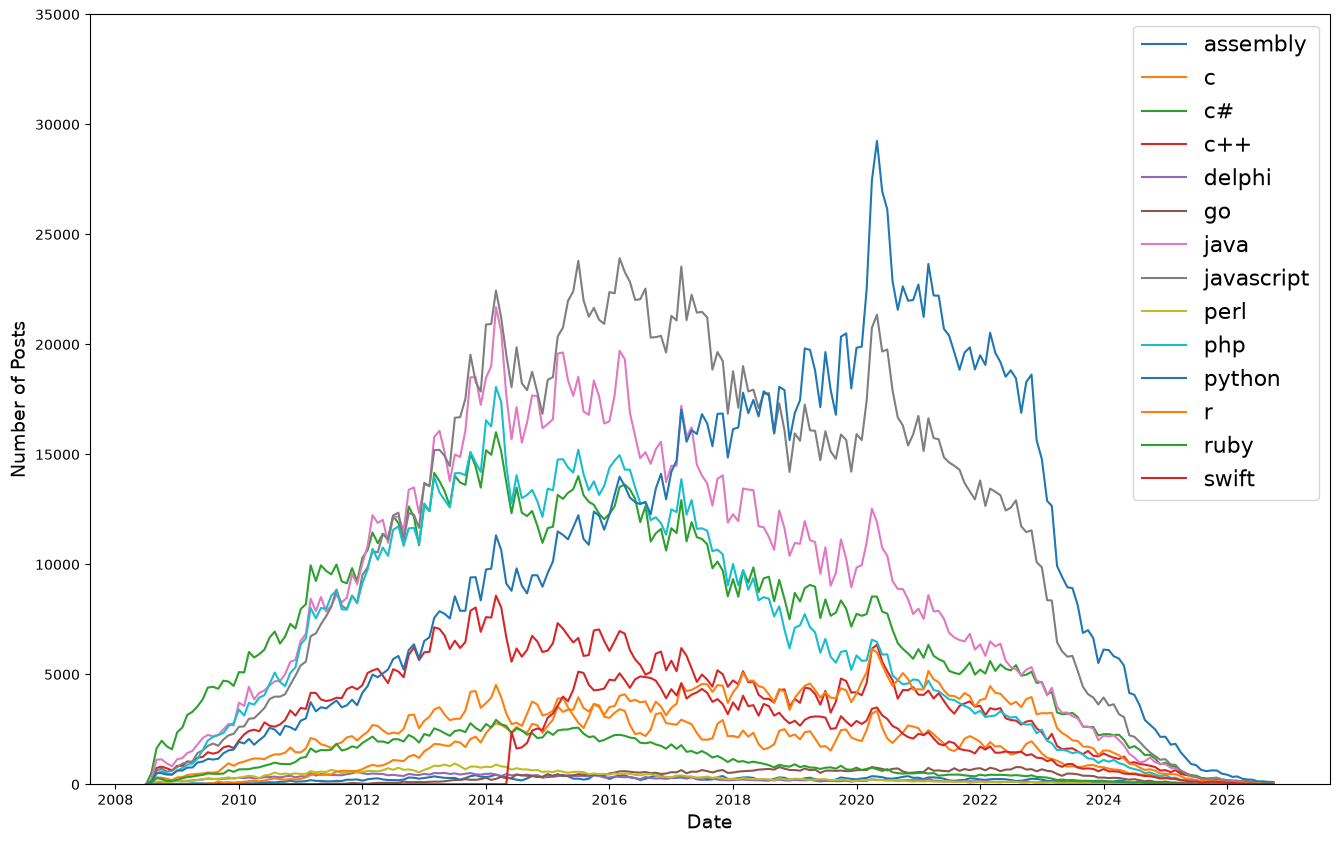

In [73]:
plt.figure(figsize=(16,10))
plt.xlabel('Date', fontsize=14)
plt.ylabel('Number of Posts', fontsize=14)
for column in reshaped_df.columns:
    plt.plot(reshaped_df.index, reshaped_df[column], label=reshaped_df[column].name)
plt.ylim(0, 35000)
plt.legend(fontsize=16)
plt.show()

# Smoothing out Time Series Data

Time series data can be quite noisy, with a lot of up and down spikes. To better see a trend we can plot an average of, say 6 or 12 observations. This is called the rolling mean. We calculate the average in a window of time and move it forward by one overservation. Pandas has two handy methods already built in to work this out: [rolling()](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.rolling.html) and [mean()](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.core.window.rolling.Rolling.mean.html). 